# Practical 5, Part II: Phase-Field Simulations with FiPy

**Materials Simulation Practical 5, implementation tasks** · Ali Ghelichkhani ([ali.ghelichkhani@fau.de](mailto:ali.ghelichkhani@fau.de)) · Supervisor: Frank Wendler
Institute of Materials Simulation (WW8), FAU Erlangen-Nürnberg · Winter semester 2026/27

The theory — the free-energy functional, the functional derivative, the Allen–Cahn and Cahn–Hilliard
equations, the finite volume discretization and the analytic equilibrium interface — is in Part I
(`report/main.pdf`). This notebook carries out the three tasks of the script.

| Task | Content | Section |
|------|---------|---------|
| 1 | 1D single-component solidification, $\delta F/\delta\phi$, effect of $f_0$, $K_\phi$, $L$ | [1](#1), [2](#2), [3](#3) |
| 2 | bulk energy density coefficient $f_0$ for Ni–Al $\gamma/\gamma'$ | [4](#4) |
| 3 | gradient energy density coefficient $K_c$, 1D interface, 2D spinodal decomposition | [5](#5), [6](#6) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fipy import CellVariable, Grid1D, Grid2D, TransientTerm, DiffusionTerm, ImplicitSourceTerm

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.autolayout": True})

<a id="1"></a>
## 1 The functional derivative (Task 1)

With

$$F = \int\Big(\underbrace{f_0\,\phi^2(1-\phi)^2}_{f_{\rm bulk}} + \underbrace{\tfrac{K_\phi}{2}|\nabla\phi|^2}_{f_{\rm grad}}\Big)\,\mathrm d\vec r,
\qquad
\frac{\delta F}{\delta\phi} = \frac{\partial f}{\partial\phi} - \nabla\cdot\frac{\partial f}{\partial(\nabla\phi)},$$

the two pieces are

$$\frac{\partial f}{\partial\phi} = 2f_0\,\phi(1-\phi)(1-2\phi),
\qquad
\frac{\partial f}{\partial(\nabla\phi)} = K_\phi\nabla\phi
\;\Rightarrow\;
\nabla\cdot\frac{\partial f}{\partial(\nabla\phi)} = K_\phi\nabla^2\phi,$$

so that

$$\boxed{\;\frac{\delta F}{\delta\phi} = 2f_0\,\phi(1-\phi)(1-2\phi) - K_\phi\nabla^2\phi\;}
\qquad\text{and}\qquad
\frac{\partial\phi}{\partial t} = -L\frac{\delta F}{\delta\phi}
= L K_\phi\nabla^2\phi - 2Lf_0\,\phi(1-\phi)(1-2\phi).$$

This is the Allen–Cahn equation: a diffusion term that smooths the profile and a reaction term that
pushes $\phi$ towards the two wells at $\phi = 0$ and $\phi = 1$. The stationary solution of Part I is

$$\phi(x) = \frac12\Big[1+\tanh\frac{x}{2\delta}\Big], \qquad
\delta = \sqrt{\frac{K_\phi}{2f_0}}, \qquad
\sigma = \frac{\sqrt{2f_0K_\phi}}{6},$$

with the interface thickness $\lambda = 4\delta$ (defined through the maximum slope) and the interface
energy $\sigma$. The two energy contributions are equal at equilibrium, $F_{\rm bulk} = F_{\rm grad} = \sigma/2$.

### Numerical treatment of the reaction term

The reaction term is destabilising near $\phi = 1/2$, where $\partial^2 f_{\rm bulk}/\partial\phi^2 < 0$.
An explicit treatment is then stable only for $\Delta t < 1/(2Lf_0)$, i.e. $\Delta t < 0.5$ for the
dimensionless parameters of the task — so $\Delta t = 1$ would already blow up. Following §3.2 of the
script we therefore split the source into $S_0 + S_1\phi$ by linearising about the old value,

$$-L\,g(\phi) \simeq \underbrace{L\big[g'(\phi^{\rm old})\phi^{\rm old} - g(\phi^{\rm old})\big]}_{S_0}
+ \underbrace{\big(-Lg'(\phi^{\rm old})\big)}_{S_1}\phi,
\qquad g(\phi) = \frac{\partial f_{\rm bulk}}{\partial\phi},$$

and hand $S_1$ to FiPy's `ImplicitSourceTerm`, which places it on the matrix diagonal where it
stabilises the solve. The diffusion term is implicit anyway.

In [2]:
def dfbulk(phi, f0):
    """df_bulk/dphi for f_bulk = f0 phi^2 (1-phi)^2."""
    return 2 * f0 * phi * (1 - phi) * (1 - 2 * phi)


def d2fbulk(phi, f0):
    """d^2 f_bulk/dphi^2."""
    return 2 * f0 * (1 - 6 * phi + 6 * phi ** 2)


def allen_cahn_1d(f0=1.0, Kphi=1.0, L=1.0, dx=1.0, dt=1.0, nx=200, nsteps=50, sweeps=5):
    """1D solidification: phi = 1 (solid) on the left, phi = 0 (liquid) on the right."""
    mesh = Grid1D(dx=dx, nx=nx)
    phi = CellVariable(mesh=mesh, name=r"$\phi$", hasOld=True)
    phi.setValue(1.0, where=mesh.cellCenters[0] < nx * dx / 2)

    history = []
    for _ in range(nsteps):
        phi.updateOld()
        old = phi.old
        g, gp = dfbulk(old, f0), d2fbulk(old, f0)
        eq = (TransientTerm() == DiffusionTerm(coeff=L * Kphi)
              + L * (gp * old - g) - ImplicitSourceTerm(coeff=L * gp))
        for _ in range(sweeps):
            eq.sweep(var=phi, dt=dt)
        grad = phi.grad[0]
        f_b = f0 * phi ** 2 * (1 - phi) ** 2
        f_g = Kphi / 2 * grad ** 2
        history.append((float((f_b * mesh.cellVolumes).sum()),
                        float((f_g * mesh.cellVolumes).sum())))
    history = np.array(history)
    return dict(x=mesh.cellCenters[0].value, phi=phi.value,
                f_bulk=(f0 * phi ** 2 * (1 - phi) ** 2).value,
                f_grad=(Kphi / 2 * phi.grad[0] ** 2).value,
                F_bulk=history[:, 0], F_grad=history[:, 1], F=history.sum(axis=1))


def delta_analytic(f0, Kphi):
    return np.sqrt(Kphi / (2 * f0))


def sigma_analytic(f0, Kphi):
    return np.sqrt(2 * f0 * Kphi) / 6


r = allen_cahn_1d()
d_a, s_a = delta_analytic(1.0, 1.0), sigma_analytic(1.0, 1.0)
print(f"analytic: delta = {d_a:.4f}, lambda = 4 delta = {4*d_a:.4f} cells, sigma = {s_a:.5f}")
print(f"numeric : F_bulk = {r['F_bulk'][-1]:.5f}, F_grad = {r['F_grad'][-1]:.5f}, "
      f"F = {r['F'][-1]:.5f}")
print(f"equipartition F_bulk/F_grad = {r['F_bulk'][-1]/r['F_grad'][-1]:.4f} (should be 1)")

analytic: delta = 0.7071, lambda = 4 delta = 2.8284 cells, sigma = 0.23570
numeric : F_bulk = 0.10968, F_grad = 0.10923, F = 0.21891
equipartition F_bulk/F_grad = 1.0041 (should be 1)


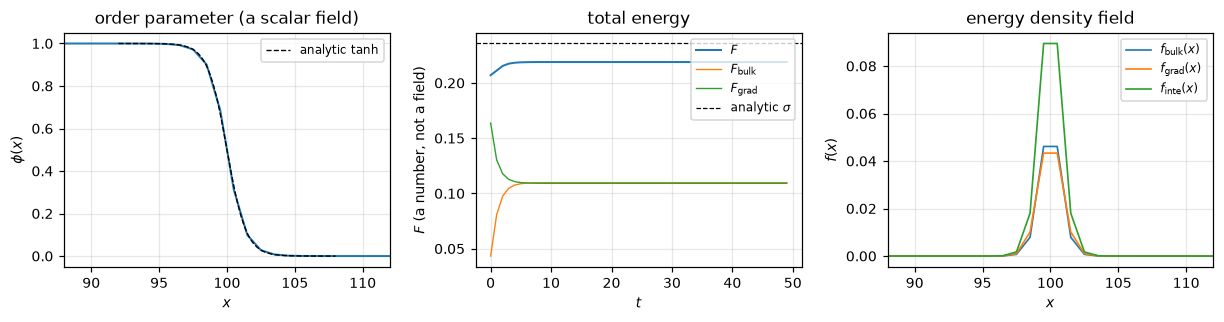

max deviation from the analytic tanh profile: 0.0178
numeric sigma = 0.21891 vs analytic 0.23570 (-7.1 %)


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11.2, 3.0))
ax[0].plot(r["x"], r["phi"], lw=1.3)
xc = np.interp(0.5, r["phi"][::-1], r["x"][::-1])
xs = np.linspace(xc - 8, xc + 8, 300)
ax[0].plot(xs, 0.5 * (1 + np.tanh(-(xs - xc) / (2 * d_a))), "k--", lw=0.9, label="analytic tanh")
ax[0].set(xlabel="$x$", ylabel=r"$\phi(x)$", xlim=(xc - 12, xc + 12),
          title="order parameter (a scalar field)")
ax[0].legend(fontsize=8)

ax[1].plot(r["F"], lw=1.3, label="$F$")
ax[1].plot(r["F_bulk"], lw=0.9, label=r"$F_{\rm bulk}$")
ax[1].plot(r["F_grad"], lw=0.9, label=r"$F_{\rm grad}$")
ax[1].axhline(s_a, color="k", ls="--", lw=0.8, label=r"analytic $\sigma$")
ax[1].set(xlabel="$t$", ylabel="$F$ (a number, not a field)", title="total energy")
ax[1].legend(fontsize=8)

ax[2].plot(r["x"], r["f_bulk"], lw=1.1, label=r"$f_{\rm bulk}(x)$")
ax[2].plot(r["x"], r["f_grad"], lw=1.1, label=r"$f_{\rm grad}(x)$")
ax[2].plot(r["x"], r["f_bulk"] + r["f_grad"], lw=1.1, label=r"$f_{\rm inte}(x)$")
ax[2].set(xlabel="$x$", ylabel="$f(x)$", xlim=(xc - 12, xc + 12), title="energy density field")
ax[2].legend(fontsize=8)
plt.show()

err = np.abs(r["phi"] - 0.5 * (1 + np.tanh(-(r["x"] - xc) / (2 * d_a))))
print(f"max deviation from the analytic tanh profile: {err.max():.4f}")
print(f"numeric sigma = {r['F'][-1]:.5f} vs analytic {s_a:.5f} "
      f"({100*(r['F'][-1]-s_a)/s_a:+.1f} %)")

The simulated profile is the analytic $\tanh$ to within a few percent and the energy decays
monotonically to a plateau — the Allen–Cahn equation is a gradient flow, so $F$ can only decrease.
The plateau sits about 7 % *below* the analytic $\sigma$. That is a discretization effect: with
$f_0 = K_\phi = 1$ the interface half-width is $\delta = 0.71$ cells and the full interface
$\lambda = 4\delta = 2.8$ cells, so the profile is barely resolved and the discrete gradient
underestimates $|\nabla\phi|^2$. Section 3 shows the error disappearing as $K_\phi$ widens the
interface.

**Why the interface does not move.** The double well $f_0\phi^2(1-\phi)^2$ is symmetric: both phases
have exactly the same bulk energy, so there is no driving force and a flat interface only relaxes to
its equilibrium shape and then stands still. Real solidification needs an asymmetric well — a tilt
$\Delta f$ between the two minima, supplied by undercooling — and the interface then moves at a
velocity $v = L\,\Delta f\,\delta$ proportional to that tilt. A curved interface would also move, by
the Gibbs–Thomson effect, at $v = L\sigma\kappa$.

<a id="2"></a>
## 2 Effect of $f_0$, $K_\phi$ and $L$

Keeping $dx = 1$ and $dt = 1$, each coefficient is varied in turn. The analytic predictions are

$$\delta = \sqrt{\frac{K_\phi}{2f_0}}, \qquad \sigma = \frac{\sqrt{2f_0K_\phi}}{6},$$

so $f_0$ and $K_\phi$ act in *opposite* directions on the width and in the *same* direction on the
energy, while $L$ appears in neither: the mobility sets only how fast equilibrium is reached.

varying f0  (K = 1, L = 1)


  f0= 0.25: lambda_num= 5.95 (4*delta= 5.66)  sigma_num=0.1159 (analytic 0.1179)


  f0= 1.00: lambda_num= 3.40 (4*delta= 2.83)  sigma_num=0.2189 (analytic 0.2357)


  f0= 4.00: lambda_num= 2.31 (4*delta= 1.41)  sigma_num=0.2837 (analytic 0.4714)

varying K_phi  (f0 = 1, L = 1)


  K= 0.25: lambda_num= 2.31 (4*delta= 1.41)  sigma_num=0.0709 (analytic 0.1179)


  K= 1.00: lambda_num= 3.40 (4*delta= 2.83)  sigma_num=0.2189 (analytic 0.2357)


  K= 4.00: lambda_num= 5.95 (4*delta= 5.66)  sigma_num=0.4635 (analytic 0.4714)

varying L  (f0 = 1, K = 1)


  L= 0.10: F after 40 steps = 0.21879, lambda_num= 3.39


  L= 0.50: F after 40 steps = 0.21890, lambda_num= 3.40


  L= 2.00: F after 40 steps = 0.21891, lambda_num= 3.40


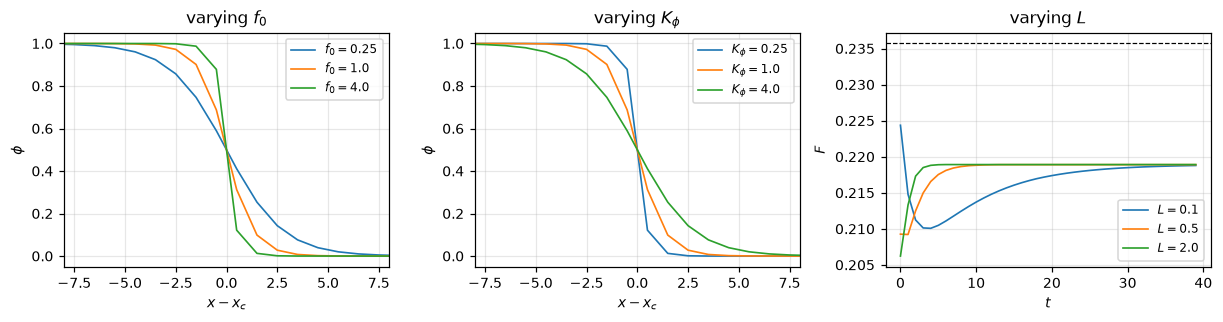

In [4]:
def interface_width(x, phi):
    """Width from the maximum slope: lambda = 1 / max|dphi/dx|."""
    slope = np.abs(np.gradient(phi, x))
    return 1.0 / slope.max()


fig, ax = plt.subplots(1, 3, figsize=(11.2, 3.0))

print("varying f0  (K = 1, L = 1)")
for f0 in (0.25, 1.0, 4.0):
    rr = allen_cahn_1d(f0=f0)
    xc = np.interp(0.5, rr["phi"][::-1], rr["x"][::-1])
    ax[0].plot(rr["x"] - xc, rr["phi"], lw=1.1, label=f"$f_0={f0}$")
    print(f"  f0={f0:5.2f}: lambda_num={interface_width(rr['x'], rr['phi']):5.2f} "
          f"(4*delta={4*delta_analytic(f0,1.0):5.2f})  "
          f"sigma_num={rr['F'][-1]:.4f} (analytic {sigma_analytic(f0,1.0):.4f})")
ax[0].set(xlabel="$x - x_c$", ylabel=r"$\phi$", xlim=(-8, 8), title=r"varying $f_0$")
ax[0].legend(fontsize=8)

print("\nvarying K_phi  (f0 = 1, L = 1)")
for K in (0.25, 1.0, 4.0):
    rr = allen_cahn_1d(Kphi=K)
    xc = np.interp(0.5, rr["phi"][::-1], rr["x"][::-1])
    ax[1].plot(rr["x"] - xc, rr["phi"], lw=1.1, label=f"$K_\\phi={K}$")
    print(f"  K={K:5.2f}: lambda_num={interface_width(rr['x'], rr['phi']):5.2f} "
          f"(4*delta={4*delta_analytic(1.0,K):5.2f})  "
          f"sigma_num={rr['F'][-1]:.4f} (analytic {sigma_analytic(1.0,K):.4f})")
ax[1].set(xlabel="$x - x_c$", ylabel=r"$\phi$", xlim=(-8, 8), title=r"varying $K_\phi$")
ax[1].legend(fontsize=8)

print("\nvarying L  (f0 = 1, K = 1)")
for L in (0.1, 0.5, 2.0):
    rr = allen_cahn_1d(L=L, nsteps=40)
    ax[2].plot(rr["F"], lw=1.1, label=f"$L={L}$")
    print(f"  L={L:5.2f}: F after 40 steps = {rr['F'][-1]:.5f}, "
          f"lambda_num={interface_width(rr['x'], rr['phi']):5.2f}")
ax[2].axhline(sigma_analytic(1.0, 1.0), color="k", ls="--", lw=0.8)
ax[2].set(xlabel="$t$", ylabel="$F$", title="varying $L$")
ax[2].legend(fontsize=8)
plt.show()

**Summary of the parameter study.**

* $f_0$ is the *height* of the double-well barrier. Raising it makes the two phases more distinct and
  penalises intermediate values of $\phi$, so the interface becomes **thinner**
  ($\delta \propto f_0^{-1/2}$) and the interface energy **larger** ($\sigma \propto f_0^{1/2}$).
* $K_\phi$ is the penalty on gradients. Raising it makes sharp interfaces expensive, so the interface
  becomes **wider** ($\delta \propto K_\phi^{1/2}$) and again **more energetic**
  ($\sigma \propto K_\phi^{1/2}$).
* $L$ is the kinetic coefficient of the non-conserved field. It appears only in the time derivative,
  so it **changes nothing at equilibrium** — the final profile and energy are identical — and only
  rescales time: doubling $L$ halves the time needed to reach the plateau.

This is precisely the structure that Tasks 2 and 3 exploit: $f_0$ is fixed by the *thermodynamics*
(the depth of the two wells and the barrier between them, which a CALPHAD assessment supplies), and
$K_\phi$ is then the one free parameter left to match the measured interface energy — while the
combination $\sqrt{K_\phi/f_0}$ must stay large enough for the interface to be resolved on the grid.

<a id="3"></a>
## 3 Explicit versus implicit, and the resolution of the interface

The script's §3.6 contrasts explicit and implicit schemes. The explicit Allen–Cahn update

$$\phi^{n+1}_i = \phi^n_i + \Delta t\left[LK_\phi\frac{\phi^n_{i+1}-2\phi^n_i+\phi^n_{i-1}}{\Delta x^2}
- L\,g(\phi^n_i)\right]$$

is stable only for $\Delta t < \Delta x^2/(2LK_\phi)$ *and* $\Delta t < 1/(L\,\max|g'|) = 1/(2Lf_0)$.
Both limits equal $0.5$ for the dimensionless parameters of the task, so $\Delta t = 1$ is beyond
them. The implicit scheme has no such restriction.

In [5]:
def allen_cahn_explicit(f0=1.0, Kphi=1.0, L=1.0, dx=1.0, dt=1.0, nx=200, nsteps=50):
    """Plain explicit finite-volume update, for comparison with the implicit FiPy solve."""
    phi = np.where(np.arange(nx) < nx // 2, 1.0, 0.0)
    for _ in range(nsteps):
        lap = (np.roll(phi, -1) - 2 * phi + np.roll(phi, 1)) / dx ** 2
        lap[0] = lap[-1] = 0.0                                  # zero-flux boundaries
        phi = phi + dt * (L * Kphi * lap - L * dfbulk(phi, f0))
        if not np.isfinite(phi).all() or np.abs(phi).max() > 1e3:
            return phi, False
    return phi, True


print(f"{'dt':>6s}{'explicit stable?':>19s}{'max|phi|':>12s}")
for dt in (0.1, 0.25, 0.4, 0.5, 0.6, 1.0):
    phi_e, ok = allen_cahn_explicit(dt=dt)
    with np.errstate(invalid="ignore"):
        m = np.nanmax(np.abs(phi_e))
    print(f"{dt:6.2f}{str(ok):>19s}{m:12.3e}")
print("\nlimit from the diffusion term : dt < dx^2/(2 L K) = 0.5")
print("limit from the reaction term  : dt < 1/(2 L f0)    = 0.5")
print("the implicit FiPy solve above ran at dt = 1 without trouble")

    dt   explicit stable?    max|phi|
  0.10               True   1.000e+00
  0.25               True   1.000e+00
  0.40               True   1.103e+00
  0.50              False   1.043e+06
  0.60              False   1.481e+09
  1.00              False   1.491e+04

limit from the diffusion term : dt < dx^2/(2 L K) = 0.5
limit from the reaction term  : dt < 1/(2 L f0)    = 0.5
the implicit FiPy solve above ran at dt = 1 without trouble


  K_phi   4*delta [cells]   sigma_num   sigma_ana    error


   0.50              2.00     0.13588     0.16667    18.5 %


   1.00              2.83     0.21891     0.23570     7.1 %


   2.00              4.00     0.32214     0.33333     3.4 %


   4.00              5.66     0.46352     0.47140     1.7 %


   9.00              8.49     0.70186     0.70711     0.7 %


  16.00             11.31     0.93888     0.94281     0.4 %


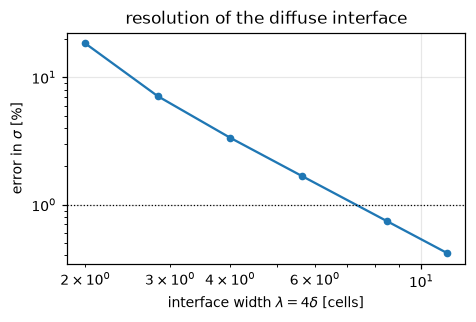


rule of thumb: the interface needs about 4-6 cells for a 1 % interface energy


In [6]:
# how the discretization error of sigma disappears as the interface becomes resolved
print(f"{'K_phi':>7s}{'4*delta [cells]':>18s}{'sigma_num':>12s}{'sigma_ana':>12s}{'error':>9s}")
Ks = [0.5, 1.0, 2.0, 4.0, 9.0, 16.0]
widths, errors = [], []
for K in Ks:
    rr = allen_cahn_1d(Kphi=K, nsteps=120, nx=320)
    s_num, s_ana = rr["F"][-1], sigma_analytic(1.0, K)
    widths.append(4 * delta_analytic(1.0, K))
    errors.append(100 * abs(s_num - s_ana) / s_ana)
    print(f"{K:7.2f}{4*delta_analytic(1.0,K):18.2f}{s_num:12.5f}{s_ana:12.5f}{errors[-1]:8.1f} %")

fig, ax = plt.subplots(figsize=(4.4, 3.0))
ax.loglog(widths, errors, "o-", ms=4)
ax.axhline(1.0, color="k", ls=":", lw=0.8)
ax.set(xlabel=r"interface width $\lambda = 4\delta$ [cells]",
       ylabel=r"error in $\sigma$ [%]", title="resolution of the diffuse interface")
plt.show()
print("\nrule of thumb: the interface needs about 4-6 cells for a 1 % interface energy")

This is the practical lesson of Task 1: the diffuse interface is a *numerical* object as much as a
physical one. It has to be wide enough to be carried by several control volumes, otherwise the
discrete gradient underestimates $f_{\rm grad}$ and the simulated interface energy is wrong — and it
has to be narrow enough that the domain is not dominated by interface. Four to six cells is the usual
compromise, and it is the constraint that drives the choice of $K_c$ in Task 3.

<a id="4"></a>
## 4 The bulk energy density coefficient of Ni–Al (Task 2)

For the two-phase $\gamma/\gamma'$ system the bulk energy density is written with the equilibrium
compositions as the two minima,

$$f_{\rm bulk} = f_0\,(c^e_{\gamma'} - c)^2\,(c - c^e_{\gamma})^2 .$$

It vanishes at $c = c^e_\gamma$ and $c = c^e_{\gamma'}$ and peaks halfway between them. Setting
$\Delta c = c^e_{\gamma'} - c^e_\gamma$ and $c = (c^e_\gamma + c^e_{\gamma'})/2$,

$$\Delta f = f_0\left(\frac{\Delta c}{2}\right)^2\left(\frac{\Delta c}{2}\right)^2
= f_0\left(\frac{\Delta c}{2}\right)^4
\qquad\Longrightarrow\qquad
\boxed{\;f_0 = \frac{\Delta f}{\left(\Delta c/2\right)^4}\;}$$

The figure in the script gives $\Delta f = 149.9\ \mathrm{J\,mol^{-1}}$ at $T = 1300$ K with the minima
read off at $c^e_\gamma = 0.16$ and $c^e_{\gamma'} = 0.23$.

Delta c = 0.070
f0 = 149.9 / (0.0350)^4 = 9.9892e+07 J/mol  ~  1e8 J/mol
   = 9.9892e+12 J/m^3   (dividing by the molar volume V_m = 1e-05 m^3/mol)


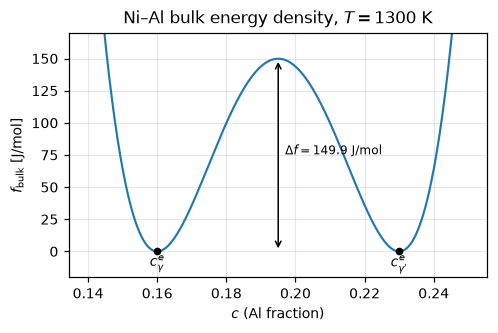


  c_gamma  c_gammap    f0 [J/mol]
    0.160     0.225     1.344e+08
    0.160     0.230     9.989e+07
    0.160     0.235     7.580e+07
    0.155     0.230     7.580e+07

-> f0 is of the order of 1e8 J/mol = 1e13 J/m^3; reading the minima off the plot to +/- 0.005 changes it by about 30 %, so only the order of magnitude is meaningful


In [7]:
DF = 149.9            # J/mol, barrier height from the figure
C_GAMMA = 0.16        # equilibrium Al fraction in gamma
C_GAMMAP = 0.23       # equilibrium Al fraction in gamma'
V_M = 1e-5            # molar volume, m^3/mol

DC = C_GAMMAP - C_GAMMA
f0_mol = DF / (DC / 2) ** 4
f0_vol = f0_mol / V_M

print(f"Delta c = {DC:.3f}")
print(f"f0 = {DF} / ({DC/2:.4f})^4 = {f0_mol:.4e} J/mol  ~  1e8 J/mol")
print(f"   = {f0_vol:.4e} J/m^3   (dividing by the molar volume V_m = {V_M:.0e} m^3/mol)")

c = np.linspace(0.14, 0.25, 400)
f = f0_mol * (C_GAMMAP - c) ** 2 * (c - C_GAMMA) ** 2
fig, ax = plt.subplots(figsize=(4.6, 3.1))
ax.plot(c, f, lw=1.4)
ax.annotate("", xy=(0.195, 0), xytext=(0.195, DF), arrowprops=dict(arrowstyle="<->", lw=1.0))
ax.text(0.197, DF / 2, rf"$\Delta f = {DF}$ J/mol", fontsize=8)
for cc, lab in [(C_GAMMA, r"$c^e_\gamma$"), (C_GAMMAP, r"$c^e_{\gamma'}$")]:
    ax.plot(cc, 0, "ko", ms=4)
    ax.text(cc, -12, lab, ha="center", fontsize=9)
ax.set(xlabel="$c$ (Al fraction)", ylabel=r"$f_{\rm bulk}$ [J/mol]", ylim=(-20, 170),
       title="Ni–Al bulk energy density, $T = 1300$ K")
plt.show()

# sensitivity to how the minima are read off the figure
print(f"\n{'c_gamma':>9s}{'c_gammap':>10s}{'f0 [J/mol]':>14s}")
for cg, cgp in [(0.16, 0.225), (0.16, 0.23), (0.16, 0.235), (0.155, 0.23)]:
    print(f"{cg:9.3f}{cgp:10.3f}{DF/((cgp-cg)/2)**4:14.3e}")
print("\n-> f0 is of the order of 1e8 J/mol = 1e13 J/m^3; reading the minima off the plot to "
      "+/- 0.005 changes it by about 30 %, so only the order of magnitude is meaningful")

<a id="5"></a>
## 5 The gradient energy density coefficient (Task 3)

With $f_{\rm grad} = \tfrac{K_c}{2}|\nabla c|^2$ and the conserved field $c$, the kinetics is
Cahn–Hilliard,

$$\frac{\partial c}{\partial t} = M V_m^2\,\nabla^2\frac{\delta F_V}{\delta c},
\qquad
\frac{\delta F_V}{\delta c} = \frac{1}{V_m}\frac{\partial f_{\rm bulk}}{\partial c} - K_c\nabla^2 c .$$

(Part I derives the factor $V_m^2$: $f_{\rm bulk}$ is given per mole and $K_c$ per unit volume, and the
mobility $M$ is defined through a molar flux.) Substituting
$u = (c-c^e_\gamma)/\Delta c \in [0,1]$ maps the problem onto the symmetric double well of Section 1
with the effective coefficients $f_0^{\rm eff} = f_{0,V}\Delta c^4$ and
$K^{\rm eff} = K_c\Delta c^2$, so the analytic results carry over:

$$\boxed{\;\delta = \frac{1}{\Delta c}\sqrt{\frac{K_c}{2f_{0,V}}},
\qquad
\sigma = \frac{\Delta c^3\sqrt{2f_{0,V}K_c}}{6}.\;}$$

Both grow as $\sqrt{K_c}$, which is what makes $K_c$ the knob for the interface energy — and also means
that the interface energy and the interface width cannot be chosen independently.

In [8]:
M_MOB = 1e-17                       # mol^2 J^-1 m^-1 s^-1
M_V = M_MOB * V_M ** 2              # m^5 J^-1 s^-1, the mobility of the volumetric formulation
DX_SCRIPT = 1e-8                    # m, the length scale given in the script
DT_SCRIPT = 1.0                     # s, the time scale given in the script
F_INTE_TARGET = (5e-3, 50e-3)       # J/m^2, the experimental window


def delta_c(Kc):
    return np.sqrt(Kc / (2 * f0_vol)) / DC


def sigma_c(Kc):
    return DC ** 3 * np.sqrt(2 * f0_vol * Kc) / 6


def Kc_for_sigma(sigma):
    return (6 * sigma / DC ** 3) ** 2 / (2 * f0_vol)


print(f"{'K_c [J/m]':>12s}{'sigma [mJ/m^2]':>17s}{'delta [m]':>13s}{'delta/dx':>11s}")
for Kc in np.logspace(-10, -4, 7):
    print(f"{Kc:12.1e}{sigma_c(Kc)*1e3:17.2f}{delta_c(Kc):13.2e}{delta_c(Kc)/DX_SCRIPT:11.3f}")

print(f"\nto hit the experimental window {F_INTE_TARGET[0]*1e3:.0f}-{F_INTE_TARGET[1]*1e3:.0f} mJ/m^2:")
print(f"  K_c = {Kc_for_sigma(F_INTE_TARGET[0]):.2e} ... {Kc_for_sigma(F_INTE_TARGET[1]):.2e} J/m")
print(f"  which gives delta = {delta_c(Kc_for_sigma(F_INTE_TARGET[0])):.2e} ... "
      f"{delta_c(Kc_for_sigma(F_INTE_TARGET[1])):.2e} m")
print(f"\nfor the interface to span >= 4 cells of the prescribed dx = {DX_SCRIPT:.0e} m one needs")
print(f"  delta >= dx, i.e. K_c >= {2*f0_vol*(DC*DX_SCRIPT)**2:.1e} J/m, which gives "
      f"sigma = {sigma_c(2*f0_vol*(DC*DX_SCRIPT)**2)*1e3:.0f} mJ/m^2")

   K_c [J/m]   sigma [mJ/m^2]    delta [m]   delta/dx
     1.0e-10             2.56     3.20e-11      0.003
     1.0e-09             8.08     1.01e-10      0.010
     1.0e-08            25.55     3.20e-10      0.032
     1.0e-07            80.80     1.01e-09      0.101
     1.0e-06           255.52     3.20e-09      0.320
     1.0e-05           808.02     1.01e-08      1.011
     1.0e-04          2555.19     3.20e-08      3.196

to hit the experimental window 5-50 mJ/m^2:
  K_c = 3.83e-10 ... 3.83e-08 J/m
  which gives delta = 6.25e-11 ... 6.25e-10 m

for the interface to span >= 4 cells of the prescribed dx = 1e-08 m one needs
  delta >= dx, i.e. K_c >= 9.8e-06 J/m, which gives sigma = 799 mJ/m^2


The two requirements pull in opposite directions, and this is the real content of Task 3.

* Matching the **measured interface energy** of 5–50 mJ/m² requires
  $K_c \approx 4\cdot10^{-10}\ldots4\cdot10^{-8}\ \mathrm{J/m}$, i.e. the lower end of (and just below)
  the range suggested in the script. The bottom of the suggested range,
  $K_c = 1\cdot10^{-7}\ \mathrm{J/m}$, gives $\sigma \approx 81\ \mathrm{mJ/m^2}$ — the right order of
  magnitude, a factor 1.6 above the window.
* **Resolving the interface** on the prescribed grid $\Delta x = 10$ nm requires
  $K_c \gtrsim 10^{-5}\ \mathrm{J/m}$, which would put $\sigma$ at 800 mJ/m², an order of magnitude too
  high.

They are incompatible because the physical interface of this alloy is of the order of a nanometre
while the prescribed cell is ten. The standard resolutions are (i) refine the grid until
$\Delta x \lesssim \delta$, which is what we do below for the quantitative work, or (ii) keep the
coarse grid and deliberately *widen* the interface by raising $K_c$ and lowering $f_{0,V}$ together so
that $\sigma \propto \sqrt{f_{0,V}K_c}$ stays fixed while $\delta \propto \sqrt{K_c/f_{0,V}}$ grows —
the "thin-interface" rescaling used in production phase-field codes. We take route (i) and choose
$K_c = 1\cdot10^{-7}\ \mathrm{J/m}$, the smallest value of the range given in the script, on a grid
with $\Delta x = \delta/3$.

In [9]:
def cahn_hilliard_1d(Kc, nx=160, dx=None, dt=None, nsteps=600, sweeps=4, start="tanh"):
    """1D equilibrium interface between gamma and gamma'."""
    d = delta_c(Kc)
    dx = d / 3 if dx is None else dx
    dt = 0.02 * d ** 4 / (M_V * Kc) if dt is None else dt
    mesh = Grid1D(dx=dx, nx=nx)
    x = mesh.cellCenters[0].value
    c = CellVariable(mesh=mesh, name="$c$", hasOld=True)
    if start == "tanh":
        c.setValue(C_GAMMA + DC * 0.5 * (1 + np.tanh((x - nx * dx / 2) / (2 * d))))
    else:
        c.setValue(C_GAMMA)
        c.setValue(C_GAMMAP, where=mesh.cellCenters[0] > nx * dx / 2)

    for _ in range(nsteps):
        c.updateOld()
        u = c.old
        d2f = f0_vol * 2 * ((C_GAMMAP - u) ** 2 - 4 * (C_GAMMAP - u) * (u - C_GAMMA)
                            + (u - C_GAMMA) ** 2)
        eq = (TransientTerm() == DiffusionTerm(coeff=M_V * d2f)
              - DiffusionTerm(coeff=(M_V, Kc)))
        for _ in range(sweeps):
            eq.sweep(var=c, dt=dt)

    g = c.grad[0].value
    f_b = f0_vol * (C_GAMMAP - c.value) ** 2 * (c.value - C_GAMMA) ** 2
    f_g = Kc / 2 * g ** 2
    return dict(x=x, c=c.value, dx=dx, dt=dt, delta=d,
                F_bulk=float((f_b * dx).sum()), F_grad=float((f_g * dx).sum()))


print(f"{'K_c [J/m]':>11s}{'dx [m]':>11s}{'F_bulk':>12s}{'F_grad':>12s}"
      f"{'F_inte [mJ/m^2]':>18s}{'analytic':>11s}")
scan = {}
for Kc in [1e-7, 1e-6, 1e-5, 1e-4]:
    res = cahn_hilliard_1d(Kc)
    scan[Kc] = res
    tot = res["F_bulk"] + res["F_grad"]
    print(f"{Kc:11.0e}{res['dx']:11.2e}{res['F_bulk']*1e3:12.3f}{res['F_grad']*1e3:12.3f}"
          f"{tot*1e3:18.3f}{sigma_c(Kc)*1e3:11.3f}")
    assert abs(res["F_bulk"] / res["F_grad"] - 1) < 0.02, "equipartition violated"

  K_c [J/m]     dx [m]      F_bulk      F_grad   F_inte [mJ/m^2]   analytic


      1e-07   3.37e-10      40.401      40.105            80.506     80.802


      1e-06   1.07e-09     127.759     126.823           254.582    255.519


      1e-05   3.37e-09     404.010     401.049           805.060    808.021


      1e-04   1.07e-08    1277.593    1268.229          2545.822   2555.186


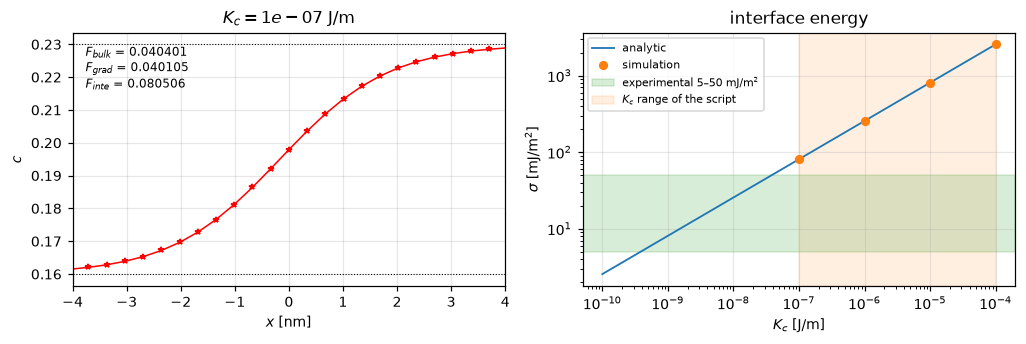

chosen K_c = 1e-07 J/m
  interface energy  = 80.51 mJ/m^2 (analytic 80.80)
  interface width   = 4 delta = 4.04 nm
  grid used         = dx 0.337 nm, i.e. 12.0 cells across the interface
  on the prescribed dx = 10 nm this interface would occupy 0.40 cells -> unresolved


In [10]:
KC_CHOSEN = 1e-7
res = scan[KC_CHOSEN]
x_nm = (res["x"] - res["x"][len(res["x"]) // 2]) * 1e9
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.2))
ax[0].plot(x_nm, res["c"], "r*-", ms=4, lw=1.0)
ax[0].axhline(C_GAMMA, color="k", ls=":", lw=0.7)
ax[0].axhline(C_GAMMAP, color="k", ls=":", lw=0.7)
ax[0].set(xlabel="$x$ [nm]", ylabel="$c$", xlim=(-4, 4),
          title=f"$K_c = {KC_CHOSEN:.0e}$ J/m")
ax[0].text(0.03, 0.95,
           f"$F_{{bulk}}$ = {res['F_bulk']:.6f}\n$F_{{grad}}$ = {res['F_grad']:.6f}\n"
           f"$F_{{inte}}$ = {res['F_bulk']+res['F_grad']:.6f}",
           transform=ax[0].transAxes, va="top", fontsize=8)

Kcs = np.logspace(-10, -4, 40)
ax[1].loglog(Kcs, sigma_c(Kcs) * 1e3, lw=1.2, label="analytic")
ax[1].loglog(list(scan), [(r_["F_bulk"] + r_["F_grad"]) * 1e3 for r_ in scan.values()],
             "o", ms=5, label="simulation")
ax[1].axhspan(5, 50, color="C2", alpha=0.18, label="experimental 5–50 mJ/m$^2$")
ax[1].axvspan(1e-7, 1e-4, color="C1", alpha=0.12, label="$K_c$ range of the script")
ax[1].set(xlabel="$K_c$ [J/m]", ylabel=r"$\sigma$ [mJ/m$^2$]", title="interface energy")
ax[1].legend(fontsize=7)
plt.show()

width_nm = 4 * res["delta"] * 1e9
print(f"chosen K_c = {KC_CHOSEN:.0e} J/m")
print(f"  interface energy  = {(res['F_bulk']+res['F_grad'])*1e3:.2f} mJ/m^2 "
      f"(analytic {sigma_c(KC_CHOSEN)*1e3:.2f})")
print(f"  interface width   = 4 delta = {width_nm:.2f} nm")
print(f"  grid used         = dx {res['dx']*1e9:.3f} nm, i.e. "
      f"{width_nm/(res['dx']*1e9):.1f} cells across the interface")
print(f"  on the prescribed dx = 10 nm this interface would occupy "
      f"{width_nm/10:.2f} cells -> unresolved")

The simulated $F_{\rm inte}$ follows the analytic $\sigma \propto \sqrt{K_c}$ over three decades of
$K_c$, and $F_{\rm bulk} = F_{\rm grad}$ to better than 2 % — the equipartition that the first integral
of the equilibrium equation predicts, and a good check that the profile really is relaxed.

**Answer to Task 3.** The smallest value of the suggested range,
$K_c = 1\cdot10^{-7}\ \mathrm{J\,m^{-1}}$, is the proper choice: it gives
$\sigma \approx 81\ \mathrm{mJ/m^2}$, the closest the range comes to the experimental
5–50 mJ/m², and an interface about 4 nm wide. Hitting the middle of the experimental window exactly
would need $K_c \approx 1\cdot10^{-8}\ \mathrm{J/m}$, a factor of ten below the suggested range, and
would halve the interface width. In either case the grid must be refined well below the
$\Delta x = 10$ nm of the script, because the physical interface of this alloy is of the order of a
nanometre.

<a id="6"></a>
## 6 Two-dimensional spinodal decomposition

The same Cahn–Hilliard equation is now solved in 2D, starting from the average composition
$c = 0.195$ — the top of the barrier, where the alloy is thermodynamically unstable — plus a small
Gaussian noise. Because $\partial^2 f_{\rm bulk}/\partial c^2 < 0$ there, the effective diffusion
coefficient $M V_m^2\,\partial^2 f/\partial c^2$ is **negative**: material diffuses *up* the
concentration gradient and fluctuations grow. This is spinodal decomposition, and the gradient term
is what stops the growth at a finite wavelength.

**Why not FiPy here.** With the FiPy formulation used for the 1D interface above (the
$\partial^2 f/\partial c^2$ term as a variable-coefficient `DiffusionTerm`), the field froze at the
initial noise level as soon as that coefficient became negative — for any time step we tried,
including ones far below the explicit limit — while the explicit solver below, applied to exactly the
same equation, decomposes as linear stability theory predicts. We therefore use a plain explicit
finite-volume update on a periodic grid,

$$c^{n+1} = c^n + \Delta t\,M V_m^2\,\nabla_h^2\!\left(\frac{1}{V_m}f'_{\rm bulk}(c^n) - K_c\nabla_h^2 c^n\right),$$

with the 5-point Laplacian $\nabla_h^2$. This is §3.6 of the script in practice: the explicit scheme
is cheap per step but its step is bounded by the fourth-order term,
$\Delta t \lesssim \Delta x^4/(8MV_m^2K_c)$, so the prescribed $\Delta t = 1$ s cannot be used and we
report physical time instead of a step count.

In [11]:
def dfbulk_c(c):
    """(1/V_m) df_bulk/dc in J/m^3."""
    return 2 * f0_vol * ((C_GAMMAP - c) ** 2 * (c - C_GAMMA) - (C_GAMMAP - c) * (c - C_GAMMA) ** 2)


def lap_periodic(a, dx):
    return (np.roll(a, 1, 0) + np.roll(a, -1, 0) + np.roll(a, 1, 1) + np.roll(a, -1, 1) - 4 * a) / dx ** 2


def cahn_hilliard_2d(Kc=KC_CHOSEN, n=128, t_end=2.0, noise=2e-3, seed=0, n_frames=5):
    d = delta_c(Kc)
    dx = d / 2
    D_max = M_V * 2 * f0_vol * DC ** 2
    dt = 0.02 * min(dx ** 4 / (M_V * Kc), dx ** 2 / D_max)
    nsteps = int(t_end / dt)
    rng = np.random.default_rng(seed)
    c = 0.195 + noise * rng.standard_normal((n, n))
    frame_steps = set(np.linspace(0, nsteps, n_frames).astype(int))
    frames, times, energies = {}, [], []
    for step in range(nsteps + 1):
        if step in frame_steps:
            frames[step * dt] = c.copy()
        if step % 500 == 0:
            gx = (np.roll(c, -1, 0) - c) / dx
            gy = (np.roll(c, -1, 1) - c) / dx
            f = f0_vol * (C_GAMMAP - c) ** 2 * (c - C_GAMMA) ** 2 + Kc / 2 * (gx ** 2 + gy ** 2)
            energies.append(f.sum() * dx * dx)
            times.append(step * dt)
        c = c + dt * M_V * lap_periodic(dfbulk_c(c) - Kc * lap_periodic(c, dx), dx)
    assert np.isfinite(c).all(), "explicit scheme went unstable"
    return frames, np.array(times), np.array(energies), dx, dt, nsteps, c


frames, times, energies, dx2, dt2, nsteps2, c2d = cahn_hilliard_2d()
L_nm = 128 * dx2 * 1e9
print(f"domain {L_nm:.1f} x {L_nm:.1f} nm, dx = {dx2*1e9:.3f} nm, dt = {dt2:.2e} s, "
      f"{nsteps2} steps to t = {nsteps2*dt2:.2f} s")
print(f"mean composition conserved: start 0.195, end {c2d.mean():.6f}")
print(f"composition range at the end: {c2d.min():.4f} ... {c2d.max():.4f} "
      f"(equilibrium {C_GAMMA} / {C_GAMMAP})")

f2 = 2 * f0_vol * ((C_GAMMAP - 0.195) ** 2 - 4 * (C_GAMMAP - 0.195) * (0.195 - C_GAMMA)
                   + (0.195 - C_GAMMA) ** 2)
k_max = np.sqrt(-f2 / (2 * KC_CHOSEN))
print(f"linear stability: fastest wavelength 2 pi / k_max = {2*np.pi/k_max*1e9:.1f} nm, "
      f"growth rate {M_V*k_max**2*(-f2/2):.2f} 1/s")
assert abs(c2d.mean() - 0.195) < 1e-3

domain 64.7 x 64.7 nm, dx = 0.505 nm, dt = 1.30e-05 s, 153331 steps to t = 2.00 s
mean composition conserved: start 0.195, end 0.195012
composition range at the end: 0.1592 ... 0.2296 (equilibrium 0.16 / 0.23)
linear stability: fastest wavelength 2 pi / k_max = 12.7 nm, growth rate 5.99 1/s


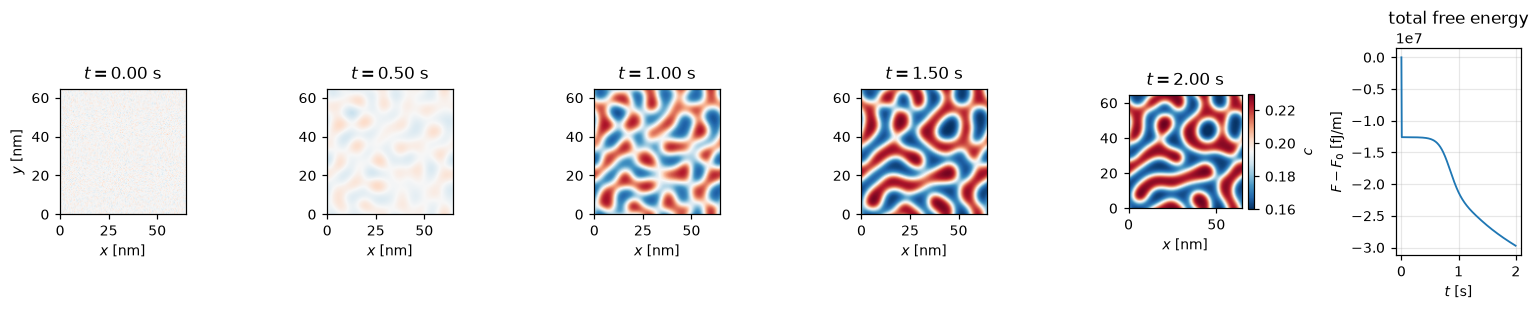

In [12]:
fig, ax = plt.subplots(1, len(frames) + 1, figsize=(14.0, 2.9))
extent = [0, L_nm, 0, L_nm]
for a, (t, field) in zip(ax, sorted(frames.items())):
    im = a.imshow(field, cmap="RdBu_r", vmin=C_GAMMA, vmax=C_GAMMAP, extent=extent, origin="lower")
    a.set(title=f"$t = {t:.2f}$ s", xlabel="$x$ [nm]")
    a.grid(False)
ax[0].set_ylabel("$y$ [nm]")
fig.colorbar(im, ax=ax[len(frames) - 1], fraction=0.046, label="$c$")
ax[-1].plot(times, (energies - energies[0]) * 1e15, lw=1.2)
ax[-1].set(xlabel="$t$ [s]", ylabel=r"$F - F_0$ [fJ/m]", title="total free energy")
plt.show()
assert energies[-1] < energies[0]

**What the pictures show.** The initial noise is amplified selectively: the Cahn–Hilliard growth rate

$$R(k) = -M V_m^2 k^2\left(\frac{1}{V_m}\frac{\partial^2 f_{\rm bulk}}{\partial c^2} + K_c k^2\right)$$

is positive only for $k < k_c = \sqrt{-f''_{\rm bulk}/(V_mK_c)}$ and peaks at
$k_{\max} = k_c/\sqrt2$, so a single wavelength dominates and the familiar interconnected,
labyrinthine two-phase morphology appears. The composition in each domain saturates at the two
equilibrium values $c^e_\gamma = 0.16$ and $c^e_{\gamma'} = 0.23$, the mean is conserved to machine
precision — which is the defining difference between the conserved Cahn–Hilliard dynamics here and the
non-conserved Allen–Cahn dynamics of Section 1 — and the total free energy decreases monotonically.
At later times the pattern coarsens: the interface area, and with it $F$, is reduced by the
Lifshitz–Slyozov–Wagner mechanism, in which large domains grow at the expense of small ones and the
characteristic length scales as $t^{1/3}$.

In the real Ni-based superalloy this is the process that produces the $\gamma'$ precipitates; the
phase-field model gets the topology and the kinetics right once $f_0$ (Task 2) and $K_c$ (Task 3) have
been fixed to the thermodynamics and to the measured interface energy.

## Summary

| Quantity | Result |
|---|---|
| $\delta F/\delta\phi$ | $2f_0\phi(1-\phi)(1-2\phi) - K_\phi\nabla^2\phi$ |
| equilibrium profile | $\phi = \tfrac12[1+\tanh(x/2\delta)]$, $\delta = \sqrt{K_\phi/2f_0}$ |
| interface energy | $\sigma = \sqrt{2f_0K_\phi}/6$, split equally between bulk and gradient |
| effect of $f_0$ | thinner interface, higher $\sigma$ |
| effect of $K_\phi$ | wider interface, higher $\sigma$ |
| effect of $L$ | kinetics only, equilibrium unchanged |
| explicit stability | $\Delta t < \min\{\Delta x^2/2LK_\phi,\ 1/2Lf_0\} = 0.5$ here |
| Ni–Al $f_0$ (Task 2) | $\approx 1\cdot10^{8}$ J/mol $= 1\cdot10^{13}$ J/m³ |
| Ni–Al $K_c$ (Task 3) | $1\cdot10^{-7}$ J/m $\to \sigma \approx 81$ mJ/m², interface $\approx 4$ nm |
| 2D | spinodal decomposition at $c = 0.195$ (explicit FV), mean conserved, $F$ decreasing |